# Quant Kraken ? reusable research workbench

Configure assets, timeframe, strategy and costs, then **Run All** in a clean kernel. Default inputs are genuine historical Coinbase Exchange crypto spot candles with historical USD?AUD reference valuation. This is a generalized research experiment, separate from the original frozen study/universe. The final holdout remains locked.

Implemented: arbitrary asset counts, UTC 24/7 crypto spot, signed research scenarios, shared capital, next-open execution, costs, covariance Kelly, chronological validation and dry-run handoff. Equities, ETFs, exchange-session FX, futures, perpetual settlement and asynchronous calendars are rejected until their adapters are implemented. Provider-listed does not establish historical universe eligibility or remove selection bias.

Provider documentation: [Coinbase historical candles](https://docs.cdp.coinbase.com/api-reference/exchange-api/rest-api/products/get-product-candles), [historical FX references](https://frankfurter.dev/v1/). No synthetic fallback occurs on provider failure.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "kraken_quant" / "research_workflow.py").is_file():
    ROOT = ROOT.parent
assert (ROOT / "kraken_quant" / "research_workflow.py").is_file(), "Launch from repository/notebooks"
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from examples.research_config import RESEARCH_UNIVERSE
from kraken_quant.research_market import asset, load_market
from kraken_quant.research_fixtures import fixture_market
from kraken_quant.research_ledger import CostModel
from kraken_quant.research_sizing import PortfolioLimits, KellyConfig
from kraken_quant.research_workflow import ResearchSpec, momentum_factory, run_research_workflow, training_sensitivity
from kraken_quant.research_report import dashboard
from kraken_quant.research_handoff import DryRunExecution
print("Repository:", ROOT)

Repository: C:\Users\avyas\kraken_quant


## Research configuration

Edit `SYMBOLS` to any supported unique Coinbase products (one or many); no exact asset count is required. The defaults come from the central research configuration. Metadata, currencies, eligibility and shortability belong to each asset. Shorting/margin are research assumptions only; defaults prohibit both.

Intervals are UTC **[start, end)**. Crypto bars are 4h, 8h, 16h, 24h, weekly (Monday) or monthly (calendar month). 16h bars are anchored to the Unix epoch and remain continuous across UTC days. Partial edge bins are dropped and diagnosed. Extend dates and reduce calibration counts appropriately for weekly/monthly experiments. Closed-market sessions are unsupported, not resampled into weekends.

Training is divided into an initial calibration prefix and a scored suffix. Validation uses a fresh strategy fitted on training only. Kelly/covariance use only the prefix for scored training and full training for validation; they remain frozen during each scored period. Embargo removes configured bars at the split. No overlapping forward-return labels are used. Optional walk-forward evaluation is available in `research_workflow.walk_forward`; folds reject overlapping OOS windows.

In [2]:
DATA_MODE = "real"  # change explicitly to "fixture" for offline mechanics tests
SYMBOLS = list(RESEARCH_UNIVERSE[:3])  # replace with your research selection
TIMEFRAME = "4h"  # "8h", "16h", "24h", "weekly", "monthly"
START = "2023-11-01T00:00:00Z"
END = "2024-03-01T00:00:00Z"
ASSETS = [asset(symbol, shortable=False) for symbol in SYMBOLS]
SPEC = ResearchSpec(timeframe=TIMEFRAME, train_end="2024-01-01T00:00:00Z",
    initial_cash=5000., calibration_bars=72, embargo_bars=1, rebalance_every=6,
    strategy_id="example-momentum", seed=7)
LIMITS = PortfolioLimits(max_gross=1., max_position=.35, max_drawdown=.20,
    daily_loss=.05, allow_short=False, allow_margin=False)
KELLY = KellyConfig(fraction=.25, minimum_observations=30, shrinkage=.5)
STRATEGY_FACTORY = momentum_factory
PARAMETERS = {"lookback": 6}
PARAMETER_GRID = [{"lookback": x} for x in (3, 6, 12)]  # disclosed, training only
FEATURE_FACTORY = None
# Explicit SCENARIO assumptions, not verified current/historical account fees.
# Unknown applicable costs (None) stop the run instead of silently becoming zero.
COSTS = {a.instrument: CostModel(commission=.001, full_spread=.001,
    slippage=.0005, impact=.0002, fx=.001, exchange=0., regulatory=0.,
    annual_borrow=None, annual_margin=None,
    label="assumed scenario; incomplete historical quote/impact coverage") for a in ASSETS}
CACHE = ROOT / ".notebook-runtime" / "market-cache"
assert DATA_MODE in ("real", "fixture")
print("Mode:", DATA_MODE, "| capital: A$", SPEC.initial_cash, "| timeframe:", TIMEFRAME)

Mode: real | capital: A$ 5000.0 | timeframe: 4h


## Market retrieval and data quality

Requests paginate hourly candles, remove identical overlapping observations and reject conflicting duplicates, gaps, invalid OHLCV, incomplete candles or unavailable products. Raw response hashes identify cache versions; the final processed panels are hashed again. No market prices are filled.

FX uses the last published daily reference, conservatively available at the next UTC midnight, carried for at most seven days. This is disclosed reference valuation, **not an executable intraday FX feed**. Conversion fees are charged on foreign-currency trades. Corporate actions do not apply to crypto spot; token migrations are unsupported. Other asset classes must supply tested adjustment/calendar adapters before use.

In [3]:
if DATA_MODE == "real":
    BARS, PROVENANCE = load_market(ASSETS, START, END, TIMEFRAME, CACHE)
else:
    BARS, PROVENANCE = fixture_market(ASSETS, START, END, TIMEFRAME, SPEC.seed)
LABEL = "GENUINE MARKET DATA ? assumed costs/reference FX" if DATA_MODE == "real" else "SYNTHETIC FIXTURE ? no historical findings"
print(LABEL)
display(pd.DataFrame([dict(asset=k.symbol, venue=k.venue, rows=len(f),
    first_open=f.index[0], last_completed=f.bar_end.iloc[-1],
    missing_values=int(f.isna().sum().sum())) for k,f in BARS.items()]))
display(PROVENANCE)

GENUINE MARKET DATA ? assumed costs/reference FX


,asset,venue,rows,first_open,last_completed,missing_values
0,BTC/USD,coinbase,726,2023-11-01 00:00:00+00:00,2024-03-01 00:00:00+00:00,0
1,ETH/USD,coinbase,726,2023-11-01 00:00:00+00:00,2024-03-01 00:00:00+00:00,0
2,XRP/USD,coinbase,726,2023-11-01 00:00:00+00:00,2024-03-01 00:00:00+00:00,0


{"Instrument(venue='coinbase', symbol='BTC/USD', base='BTC', quote='USD', market_type='spot')": {'market': {'provider': 'coinbase-exchange',
   'product': 'BTC-USD',
   'start': '2023-11-01T00:00:00+00:00',
   'end': '2024-03-01T00:00:00+00:00',
   'native_timeframe': '1h',
   'schema': 1,
   'dataset_sha256': 'c2b62a6161e7b32d9c6dc6f867ea3c6a750041f5e8b1ad2dbaf8b246570d1dc4',
   'retrieved_at': '2026-10-20T10:26:56.006448+00:00',
   'diagnostics': {'rows': 2904,
    'identical_duplicates_removed': 9,
    'missing_bars': 0,
    'calendar': '24/7',
    'timezone': 'UTC',
    'fabricated_prices': False},
   'genuine_market_data': True,
   'corporate_actions': 'not applicable to crypto spot; token migrations unsupported'},
  'aggregation': {'rows': 2904,
   'identical_duplicates_removed': 0,
   'missing_bars': 0,
   'calendar': '24/7',
   'timezone': 'UTC',
   'fabricated_prices': False,
   'timeframe': '4h',
   'complete_bars': 726,
   'omitted_edge_hours': 0},
  'fx': {'source': 'frankf

## Plug-in strategy and evaluation

A factory `(parameters, seed)` returns any object implementing `target_weights(context)`: a mapping from `Instrument` to signal strength in [-1,1] (long/short/flat), or `None` to hold units. Context includes completed OHLCV, optional feature objects, portfolio positions, cash and equity. Cross-sectional and single-asset strategies use the same interface.

An optional `fit(training_frames)` method calibrates a model before its period; it never receives validation data. A separate `feature_factory` can return a callable `(histories, timestamp)` with its own training-only `fit`. Declare `required_features` on strategies that require a builder. `rebalance_every` controls signal evaluation in completed bars. All positions share one funded AUD account. Reversals, shorts and borrowing require explicit eligibility, limits and cost assumptions.

Kelly solves a shrunk, regularized covariance problem using cost-adjusted AUD return estimates. The default conservative proxy subtracts a round trip per bar; it may correctly recommend **flat** when estimated returns do not cover costs. It does not turn negative long net returns caused by fees into fictitious short alpha. Hard risk limits override Kelly. Calibration results are exploratory IS; validation must not be used repeatedly for parameter selection and then described as unseen.

In [4]:
RUN = run_research_workflow(BARS, ASSETS, STRATEGY_FACTORY,
    parameters=PARAMETERS, spec=SPEC, costs=COSTS, limits=LIMITS,
    kelly=KELLY, feature_factory=FEATURE_FACTORY, provenance=PROVENANCE,
    registry_directory=ROOT / ".notebook-runtime" / "general-trials",
    parameter_grid=PARAMETER_GRID)
assert RUN.train.reconcile() and RUN.validation.reconcile()
print(LABEL)
print("Cost coverage:", RUN.manifest["cost_coverage"])
display(RUN.table)
print("Predeclared training-only parameter sensitivity; no automatic selection")
display(RUN.sensitivity)
display(pd.DataFrame({period: estimate.raw.rename(index=lambda k:k.symbol)
    for period,estimate in RUN.estimates.items()}))
print({period: dict(status=e.status, observations=e.observations, fitted_through=e.fitted_through)
       for period,e in RUN.estimates.items()})

GENUINE MARKET DATA ? assumed costs/reference FX
Cost coverage: all applicable spot categories explicit; execution/FX estimates are assumptions, historical quote coverage incomplete


,net_pnl_aud,net_return,annualized_net_return,net_sharpe,net_sortino,net_max_drawdown,net_calmar,annualized_net_volatility,net_bar_win_rate,net_bar_profit_factor,net_trade_win_rate,net_trade_profit_factor,net_closed_trade_pnl_aud,closed_trade_count,turnover,fill_count,total_costs_aud,gross_mark_pnl_aud,periods_per_year,elapsed_years
in-sample,0.000000,0.000000,0.000000,NaN,NaN,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,0.0,0.0,0.000000,0.0,0.000000,0.000000,2191.455,0.133701
out-of-sample,0.000000,0.000000,0.000000,NaN,NaN,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,0.0,0.0,0.000000,0.0,0.000000,0.000000,2191.455,0.163818
in-sample benchmark,-31.517415,-0.006303,-0.046194,0.103083,0.138793,0.119555,-0.386385,0.427376,0.535836,0.993439,NaN,NaN,0.0,0.0,1.009097,3.0,15.948963,-15.568451,2191.455,0.133701
out-of-sample benchmark,1710.342036,0.342068,5.025302,4.259887,6.614462,0.159144,31.577075,0.444907,0.543175,1.302434,NaN,NaN,0.0,0.0,0.942641,3.0,15.948963,1726.290999,2191.455,0.163818


Predeclared training-only parameter sensitivity; no automatic selection


,parameters,period,net_pnl_aud,net_return,annualized_net_return,net_sharpe,net_sortino,net_max_drawdown,net_calmar,annualized_net_volatility,...,net_trade_win_rate,net_trade_profit_factor,net_closed_trade_pnl_aud,closed_trade_count,turnover,fill_count,total_costs_aud,gross_mark_pnl_aud,periods_per_year,elapsed_years
0,"{""lookback"": 3}",training only,0.0,0.0,0.0,NaN,NaN,0.0,NaN,0.0,...,NaN,NaN,0.0,0,0.0,0,0.0,0.0,2191.455,0.133701
1,"{""lookback"": 6}",training only,0.0,0.0,0.0,NaN,NaN,0.0,NaN,0.0,...,NaN,NaN,0.0,0,0.0,0,0.0,0.0,2191.455,0.133701
2,"{""lookback"": 12}",training only,0.0,0.0,0.0,NaN,NaN,0.0,NaN,0.0,...,NaN,NaN,0.0,0,0.0,0,0.0,0.0,2191.455,0.133701


,in-sample,out-of-sample
BTC/USD,0.0,0.0
ETH/USD,0.0,0.0
XRP/USD,0.0,0.0


{'in-sample': {'status': 'regularized training-only cost-adjusted estimate', 'observations': 71, 'fitted_through': Timestamp('2023-11-13 00:00:00+0000', tz='UTC')}, 'out-of-sample': {'status': 'regularized training-only cost-adjusted estimate', 'observations': 365, 'fitted_through': Timestamp('2024-01-01 00:00:00+0000', tz='UTC')}}


## Standard dashboard ? net accounting throughout

All performance, rolling Sharpe, costs, exposures and attribution come from reconciled ledgers. Metrics annualize using actual elapsed time and observation counts; crypto uses 365.2425 days/year. Undefined ratios appear as NaN. Short samples and serial dependence limit annualization. FIFO closed-quantity PnL includes allocated entry, exit and holding costs; unrealized open-position PnL remains in net equity. Net bar win rate/profit factor are separately labelled.

The equal-weight buy-and-hold benchmark uses the same capital, timing and costs, fully funded with no Kelly or strategy stops. IS and OOS are independent A$5,000 accounts; they are not spliced into a fictitious continuous portfolio.

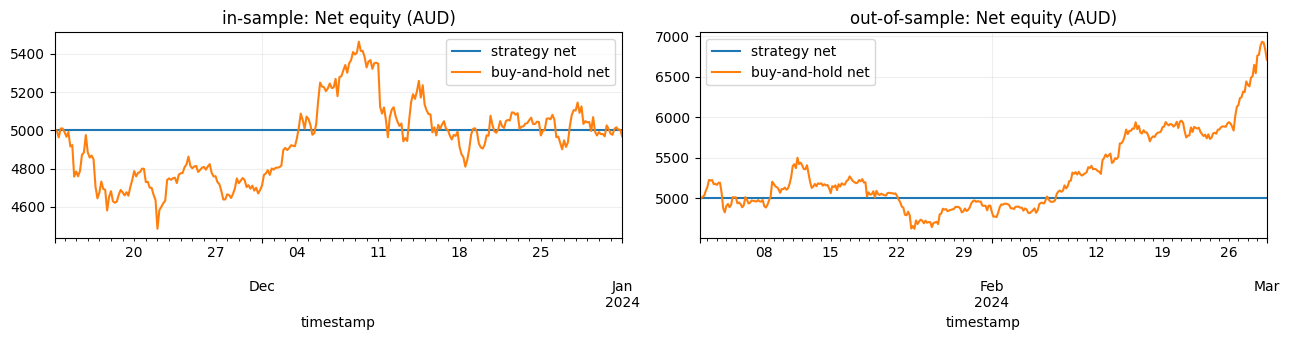

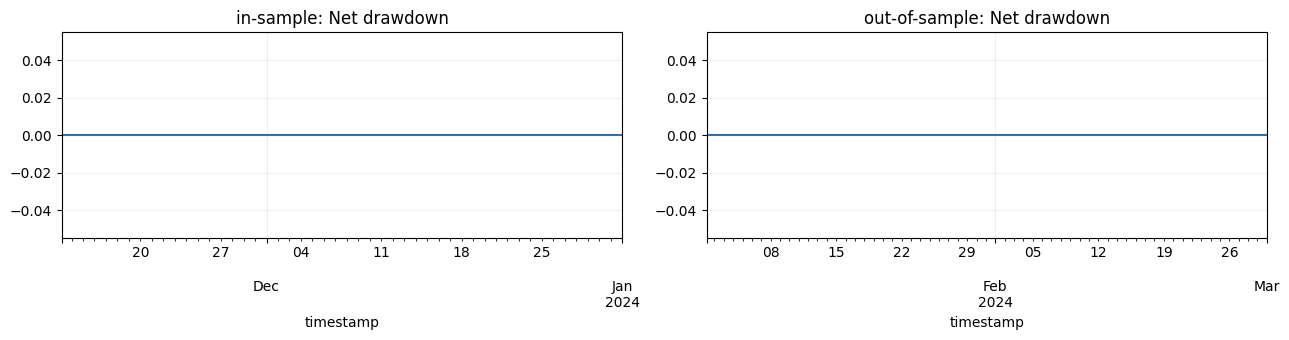

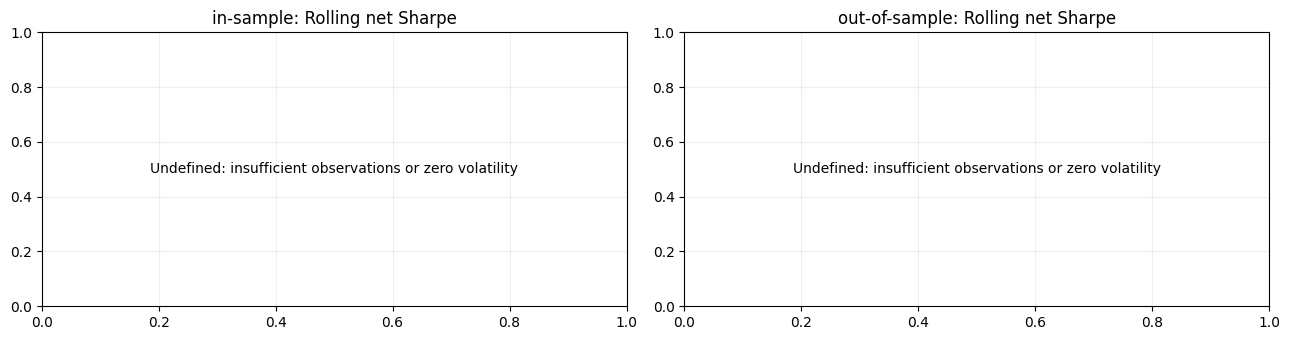

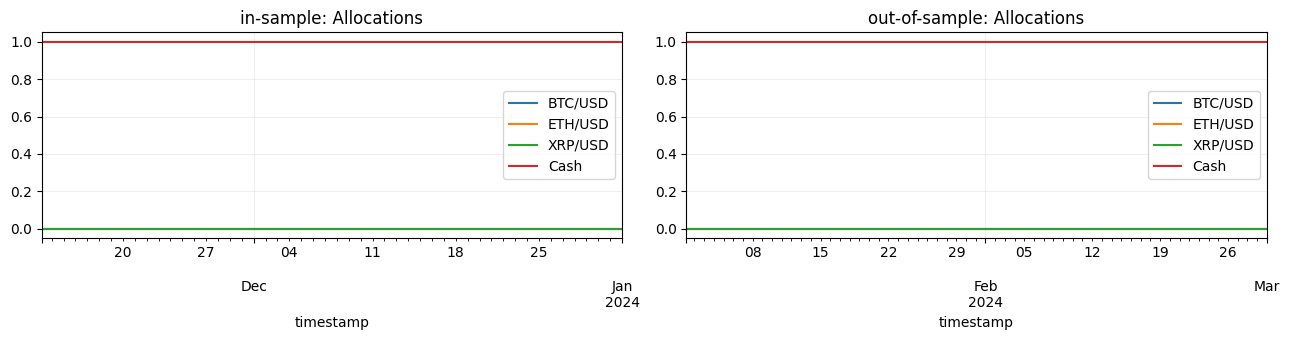

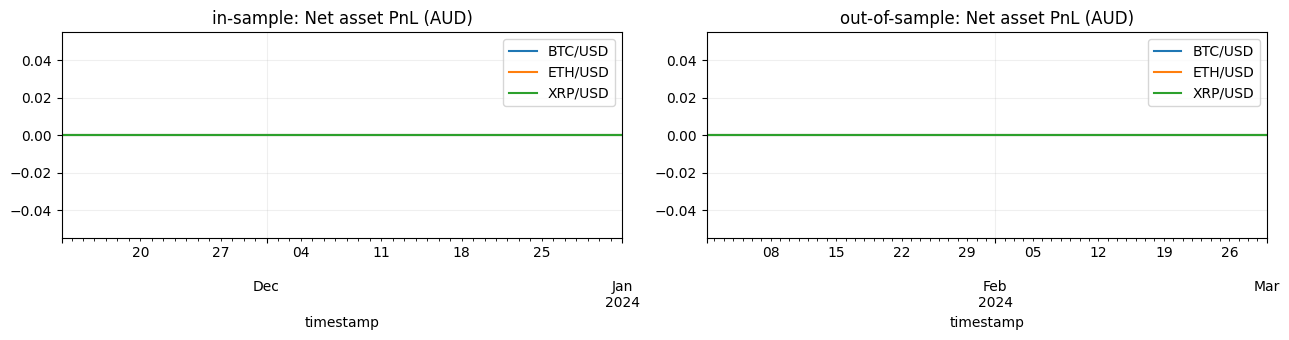

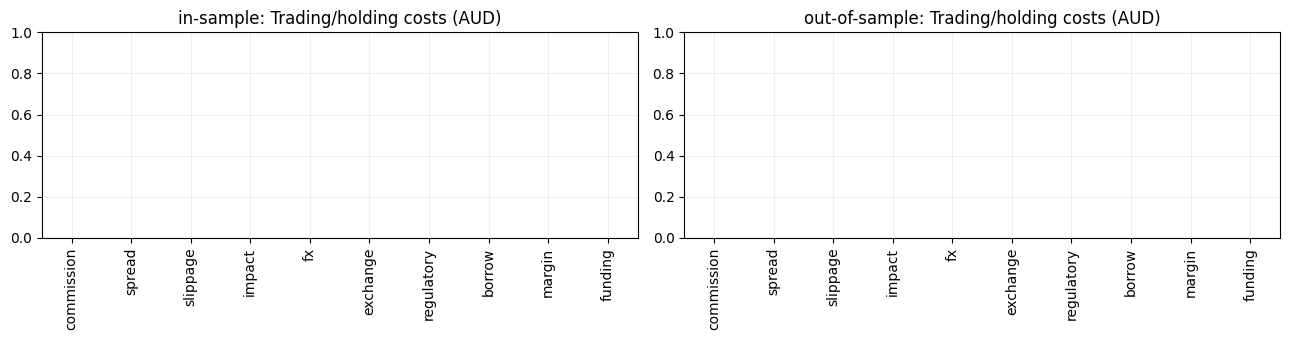

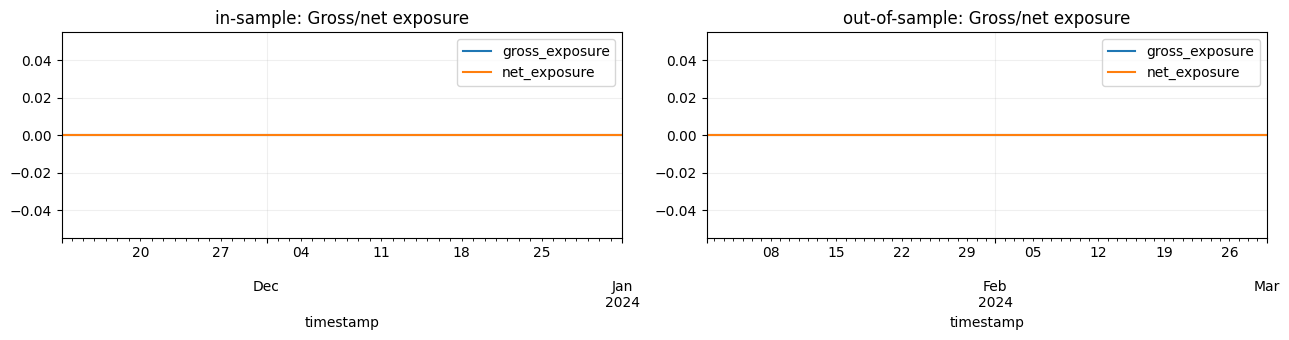

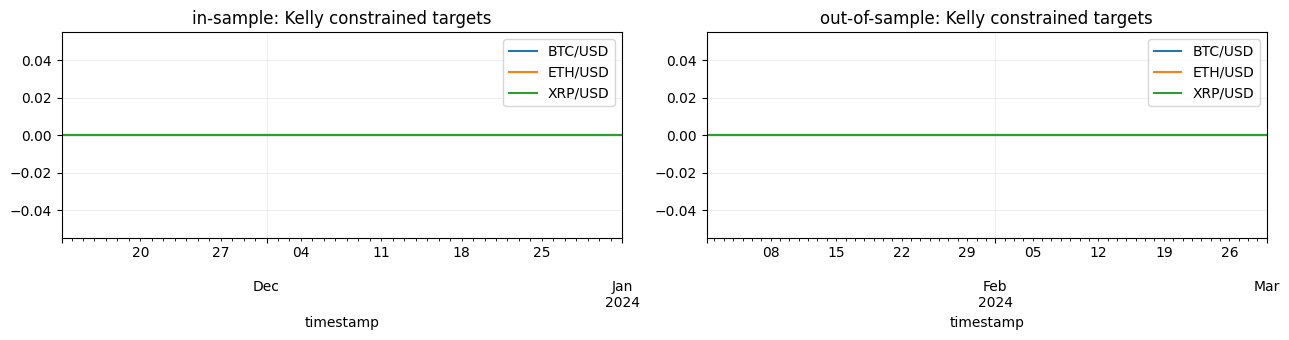

in-sample cost breakdown (AUD)


,cost_aud
commission,0.0
spread,0.0
slippage,0.0
impact,0.0
fx,0.0
exchange,0.0
regulatory,0.0
borrow,0.0
margin,0.0
funding,0.0


in-sample net asset PnL attribution (AUD)


,net_pnl_aud
BTC/USD,0.0
ETH/USD,0.0
XRP/USD,0.0


in-sample fills and net FIFO closed trades


...

out-of-sample net asset PnL attribution (AUD)


,net_pnl_aud
BTC/USD,0.0
ETH/USD,0.0
XRP/USD,0.0


out-of-sample fills and net FIFO closed trades


""


""


In [5]:
FIGURES = dashboard(RUN)
for number, figure in enumerate(FIGURES, 1):
    display(figure)
    (ROOT / ".notebook-runtime" / "figures").mkdir(parents=True, exist_ok=True)
    figure.savefig(ROOT / ".notebook-runtime" / "figures" / f"dashboard-{number}.png", dpi=110)
    plt.close(figure)
for period, result in (("in-sample", RUN.train), ("out-of-sample", RUN.validation)):
    print(period, "cost breakdown (AUD)")
    display(result.costs.sum().to_frame("cost_aud"))
    print(period, "net asset PnL attribution (AUD)")
    display(result.attribution.sum().rename(index=lambda k:k.symbol).to_frame("net_pnl_aud"))
    print(period, "fills and net FIFO closed trades")
    display(result.trades)
    display(result.closed_trades)

## Next eligible allocation and safe handoff

Targets use the latest completed bar, current simulated positions, the frozen training estimate, hard constraints and estimated rebalancing costs. The next 24/7 bar opens at the completed bar's end; the rebalance schedule may delay eligibility. A final-bar signal preview uses the latest observations without changing historical fills. Recompute when a future scheduled boundary arrives. The following bar's end is also reported. Historical targets are **not current executable orders**. Price gaps, latency, FX and liquidity can change achievable fills. Asynchronous markets are rejected until an execution calendar scheduler exists.

The tested `DryRunExecution.submit_target_weights` contract requires independently reconciled account balances, fresh AUD bid/ask quotes and lot/minimum/fee rules. It checks freshness, long-only spot eligibility, buying power and risk approval, and returns rounded intents without sending orders. Research shorts require a future tested borrow/margin broker adapter. The repository's production adapter still has no live transport. Running this notebook never submits trades.

In [6]:
display(RUN.recommendation.drop(columns=["instrument"]))
EXECUTION = DryRunExecution()
# A separate, explicitly configured caller may supply fresh snapshots:
# EXECUTION.submit_target_weights(RUN.recommendation, now=..., account=...,
#     quotes=..., rules=..., max_gross=LIMITS.max_gross,
#     max_position=LIMITS.max_position)  # dry-run only
assert RUN.manifest["final_holdout"] == "locked"
ARTIFACT_DIRECTORY = RUN.write(ROOT / ".notebook-runtime" / "general-results")
print("Immutable ledgers, report, recommendations and manifest:", ARTIFACT_DIRECTORY)
print("Completed:", LABEL, "| final holdout locked | no orders submitted")

,asset,decision_timestamp,next_execution_timestamp,following_bar_end,current_weight,target_weight,required_weight_change,direction,estimated_cost_aud,cash_allocation,gross_exposure,net_exposure,kelly_raw,eligible,risk_status,valuation_price_aud,portfolio_equity_aud,note
0,BTC/USD,2024-03-01 00:00:00+00:00,2024-03-01 08:00:00+00:00,2024-03-01 12:00:00+00:00,0.0,0.0,0.0,flat,0.0,1.0,0.0,0.0,0.0,True,ok,94283.003133,5000.0,historical target; latest quotes/reconciliatio...
1,ETH/USD,2024-03-01 00:00:00+00:00,2024-03-01 08:00:00+00:00,2024-03-01 12:00:00+00:00,0.0,0.0,0.0,flat,0.0,1.0,0.0,0.0,0.0,True,ok,5150.017158,5000.0,historical target; latest quotes/reconciliatio...
2,XRP/USD,2024-03-01 00:00:00+00:00,2024-03-01 08:00:00+00:00,2024-03-01 12:00:00+00:00,0.0,0.0,0.0,flat,0.0,1.0,0.0,0.0,0.0,True,ok,0.904934,5000.0,historical target; latest quotes/reconciliatio...


Immutable ledgers, report, recommendations and manifest: C:\Users\avyas\kraken_quant\.notebook-runtime\general-results\41c5d4254589da74d1e6d1e8c1e435f67c2b11fd0225d4592cd1d46dccf71bfc
Completed: GENUINE MARKET DATA ? assumed costs/reference FX | final holdout locked | no orders submitted


## Interpretation and limits

This framework executes research; successful execution is not profitability evidence. Cost rates, constant market impact, borrow/margin scenarios and reference FX remain disclosed estimates. Full fills, fractional units and next-open latency are optimistic. Real short availability, derivative funding, corporate-action accounting and closed-market sessions are not implemented. Unsupported configurations fail rather than quietly omitting material costs.

Risk breaches are detected at portfolio marks and flatten at the next eligible open; gaps can exceed limits. No strategy receives future candles through the interface. Arbitrary Python plug-ins are trusted researcher code, not a hostile-code sandbox. Data and code hashes, selected metadata, windows, costs, Kelly/risk configuration, seed, revision, environment and net metrics are included in the experiment manifest. Trial registration and final holdout locks reuse the existing project controls.